#Проект №9 — Аналитика: Титаник
**Датасет:** `tested.csv` (пассажиры Титаника)
[ссылка на датасет](https://www.kaggle.com/datasets/brendan45774/test-file)

**Тема исследования:** цена билета, классовое расслоение и выживаемость

### Вопросы:
1. Как распределена цена билета внутри каждого класса? — boxplot + статистика
2. Есть ли «эффект дохода»: зависимость выживания от цены? — корреляция + группировка
3. Окупается ли покупка дорогого билета? — t-test
4. Семейный статус влияет на готовность платить? — группировка SibSp+Parch

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

plt.rcParams.update({
    'figure.facecolor': '#F8F9FA',
    'axes.facecolor':   '#FFFFFF',
    'axes.spines.top':  False,
    'axes.spines.right': False,
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'font.size':        11,
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
})

print('Библиотеки загружены')

Библиотеки загружены


##Загрузка и предобработка данных

In [4]:
df = pd.read_csv('tested.csv')

df = df[df['Fare'] > 0].copy()

# Семейный размер
df['FamilySize'] = df['SibSp'] + df['Parch']
df['FamilyGroup'] = df['FamilySize'].apply(
    lambda x: 'Один' if x == 0 else ('Малая (1-2)' if x <= 2 else 'Большая (3+)')
)

class_names = {1: '1-й класс', 2: '2-й класс', 3: '3-й класс'}
df['PclassLabel'] = df['Pclass'].map(class_names)

palette_label = {'1-й класс': '#2196F3', '2-й класс': '#FF9800', '3-й класс': '#4CAF50'}

print(f'Строк: {len(df)}, колонок: {len(df.columns)}')
df[['Pclass', 'Fare', 'Survived', 'FamilyGroup']].describe().round(2)

Строк: 415, колонок: 15


,Pclass,Fare,Survived
count,415.00,415.00,415.00
mean,2.27,35.80,0.37
std,0.84,55.99,0.48
min,1.00,3.17,0.00
25%,1.00,7.90,0.00
50%,3.00,14.45,0.00
75%,3.00,31.50,1.00
max,3.00,512.33,1.00


##Вопрос 1: Как распределена цена билета внутри каждого класса?

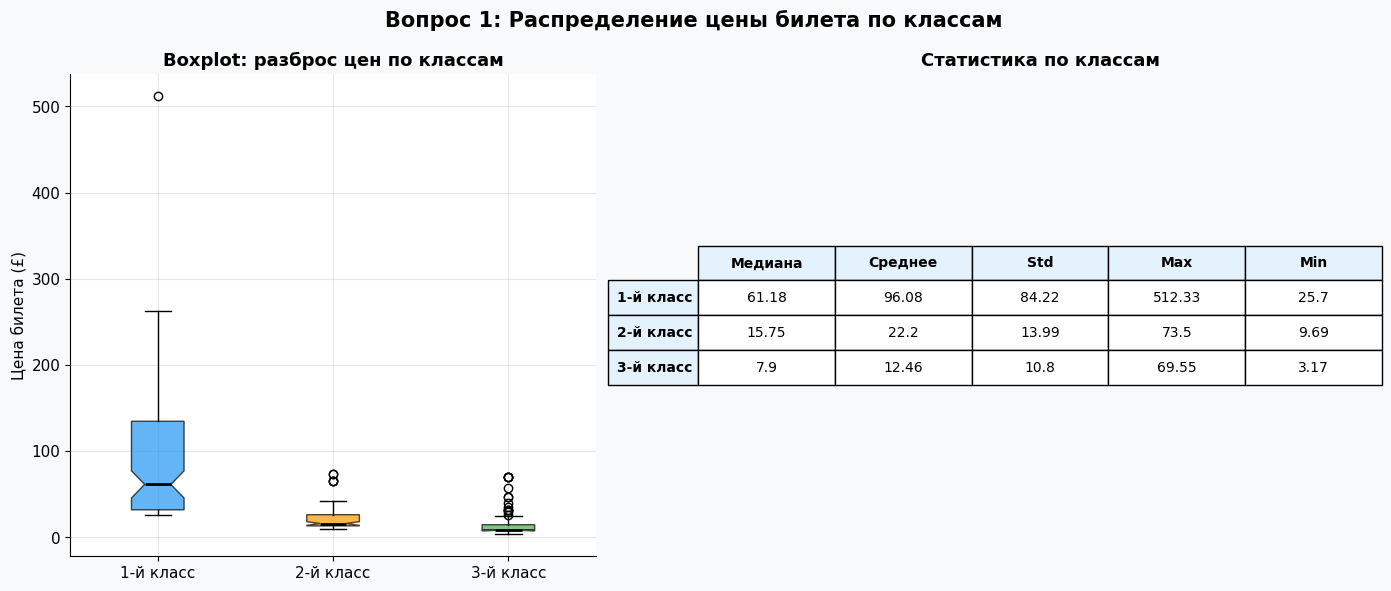

Вывод:
IQR по классам: {1: 102.82079999999999, 2: 13.0, 3: 6.65}
1-й класс: огромный разброс — от стандартных кают до апартаментов.
2-й класс: умеренный, предсказуемый диапазон цен.
3-й класс: почти все платили одинаково (~7-15£).


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Вопрос 1: Распределение цены билета по классам', fontsize=15, fontweight='bold')

# Boxplot
ax1 = axes[0]
data_by_class = [df[df['Pclass'] == c]['Fare'].values for c in [1, 2, 3]]
bp = ax1.boxplot(data_by_class, patch_artist=True, notch=True,
                 medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], ['#2196F3', '#FF9800', '#4CAF50']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax1.set_xticks([1, 2, 3])
ax1.set_xticklabels(['1-й класс', '2-й класс', '3-й класс'])
ax1.set_ylabel('Цена билета (£)')
ax1.set_title('Boxplot: разброс цен по классам')

# Таблица статистики
stats_df = df.groupby('PclassLabel')['Fare'].agg(
    Медиана='median', Среднее='mean', Std='std', Max='max', Min='min'
).round(2)
ax2 = axes[1]
ax2.axis('off')
table = ax2.table(
    cellText=stats_df.values,
    rowLabels=stats_df.index,
    colLabels=stats_df.columns,
    cellLoc='center', loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.3, 2)
for (row, col), cell in table.get_celld().items():
    if row == 0 or col == -1:
        cell.set_facecolor('#E3F2FD')
        cell.set_text_props(fontweight='bold')
ax2.set_title('Статистика по классам')

plt.tight_layout()
plt.show()

print('Вывод:')
q1_iqr = df.groupby('Pclass')['Fare'].agg(lambda x: x.quantile(0.75) - x.quantile(0.25))
print(f'IQR по классам: {q1_iqr.to_dict()}')
print('1-й класс: огромный разброс — от стандартных кают до апартаментов.')
print('2-й класс: умеренный, предсказуемый диапазон цен.')
print('3-й класс: почти все платили одинаково (~7-15£).')

##Вопрос 2: Есть ли «эффект дохода» — зависимость выживания от цены?

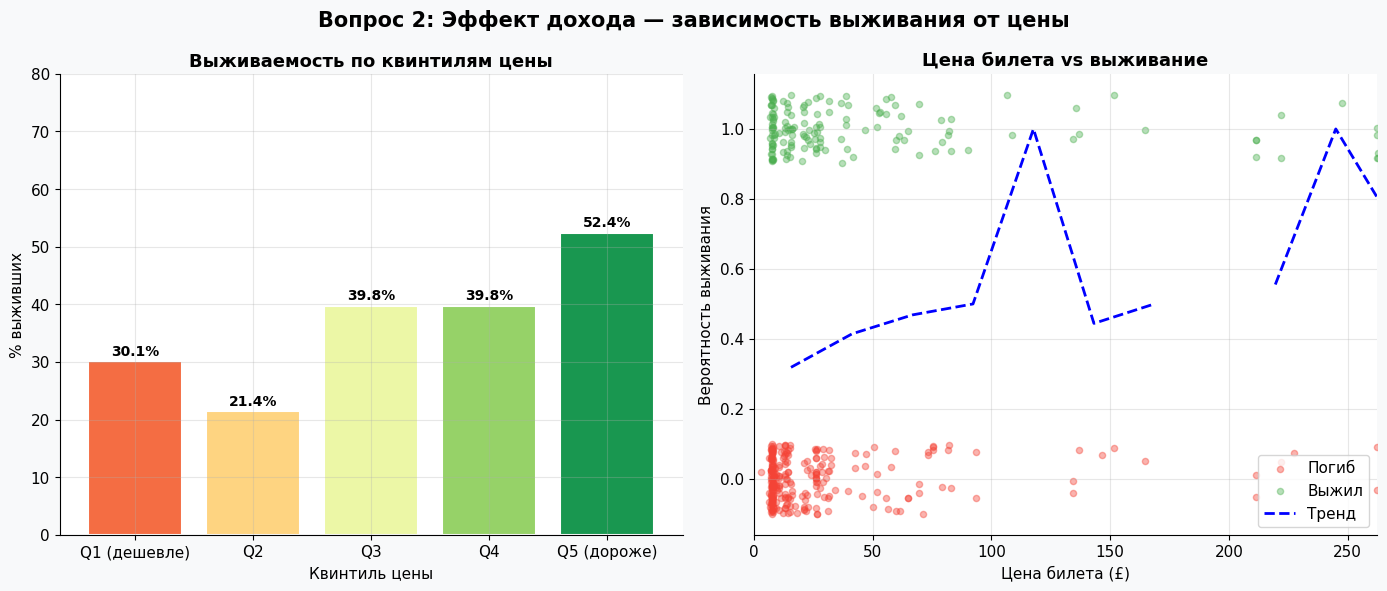

Корреляция Fare <-> Survived: r=0.190, p=0.0001
Выживаемость Q1 (дешёвые): 30.1%
Выживаемость Q5 (дорогие): 52.4%
Эффект дохода подтверждён: более дорогой билет — выше шанс выжить.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Вопрос 2: Эффект дохода — зависимость выживания от цены', fontsize=15, fontweight='bold')

# Квинтили по цене
df['FareQuintile'] = pd.qcut(df['Fare'], q=5, labels=['Q1 (дешевле)', 'Q2', 'Q3', 'Q4', 'Q5 (дороже)'])
survival_by_fare = df.groupby('FareQuintile')['Survived'].mean() * 100

ax = axes[0]
bars = ax.bar(survival_by_fare.index, survival_by_fare.values,
              color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, 5)), edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, survival_by_fare.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=10)
ax.set_ylabel('% выживших')
ax.set_xlabel('Квинтиль цены')
ax.set_title('Выживаемость по квинтилям цены')
ax.set_ylim(0, 80)

# Тренд: цена vs выживание
ax2 = axes[1]
survived = df[df['Survived'] == 1]
died = df[df['Survived'] == 0]
ax2.scatter(died['Fare'], np.random.uniform(-0.1, 0.1, len(died)),
            alpha=0.4, color='#F44336', label='Погиб', s=20)
ax2.scatter(survived['Fare'], np.random.uniform(0.9, 1.1, len(survived)),
            alpha=0.4, color='#4CAF50', label='Выжил', s=20)
bins = pd.cut(df['Fare'], bins=20)
lr_data = df.groupby(bins)['Survived'].mean()
bin_centers = [interval.mid for interval in lr_data.index]
ax2.plot(bin_centers, lr_data.values, 'b--', linewidth=2, label='Тренд')
ax2.set_xlabel('Цена билета (£)')
ax2.set_ylabel('Вероятность выживания')
ax2.set_title('Цена билета vs выживание')
ax2.legend()
ax2.set_xlim(0, df['Fare'].quantile(0.99))

plt.tight_layout()
plt.show()

corr, pval = stats.pointbiserialr(df['Survived'], df['Fare'])
print(f'Корреляция Fare <-> Survived: r={corr:.3f}, p={pval:.4f}')
print(f'Выживаемость Q1 (дешёвые): {survival_by_fare.iloc[0]:.1f}%')
print(f'Выживаемость Q5 (дорогие): {survival_by_fare.iloc[-1]:.1f}%')
print('Эффект дохода подтверждён: более дорогой билет — выше шанс выжить.')

##Вопрос 3: Окупается ли покупка дорогого билета? (t-test)

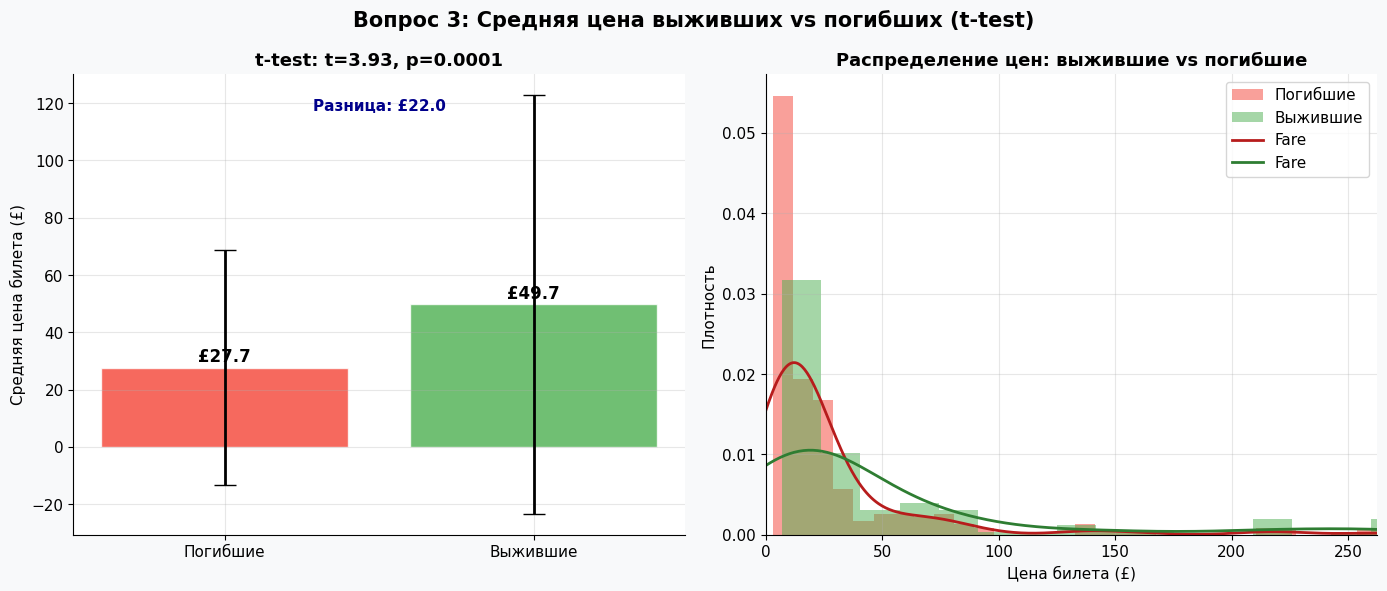

Средняя цена выживших: £49.75
   Средняя цена погибших:  £27.74
   t=3.925, p=0.000102
Разница статистически значима (p < 0.05): дорогой билет коррелирует с выживанием.


In [7]:
survived_fares = df[df['Survived'] == 1]['Fare']
died_fares = df[df['Survived'] == 0]['Fare']
t_stat, p_val = stats.ttest_ind(survived_fares, died_fares)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Вопрос 3: Средняя цена выживших vs погибших (t-test)', fontsize=15, fontweight='bold')

ax = axes[0]
groups = ['Погибшие', 'Выжившие']
means = [died_fares.mean(), survived_fares.mean()]
stds  = [died_fares.std(), survived_fares.std()]
bars = ax.bar(groups, means, yerr=stds, capsize=8,
              color=['#F44336', '#4CAF50'], alpha=0.8, edgecolor='white',
              error_kw=dict(elinewidth=2))
for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, mean + 2,
            f'£{mean:.1f}', ha='center', fontweight='bold', fontsize=12)
ax.set_ylabel('Средняя цена билета (£)')
ax.set_title(f't-test: t={t_stat:.2f}, p={p_val:.4f}')
ax.annotate(f'Разница: £{means[1]-means[0]:.1f}', xy=(0.5, 0.92),
            xycoords='axes fraction', ha='center', fontsize=11,
            color='darkblue', fontweight='bold')

ax2 = axes[1]
ax2.hist(died_fares, bins=30, alpha=0.5, color='#F44336', label='Погибшие', density=True)
ax2.hist(survived_fares, bins=30, alpha=0.5, color='#4CAF50', label='Выжившие', density=True)
died_fares.plot.kde(ax=ax2, color='#B71C1C', linewidth=2)
survived_fares.plot.kde(ax=ax2, color='#2E7D32', linewidth=2)
ax2.set_xlabel('Цена билета (£)')
ax2.set_ylabel('Плотность')
ax2.set_title('Распределение цен: выжившие vs погибшие')
ax2.legend()
ax2.set_xlim(0, df['Fare'].quantile(0.99))

plt.tight_layout()
plt.show()

print(f'Средняя цена выживших: £{survived_fares.mean():.2f}')
print(f'   Средняя цена погибших:  £{died_fares.mean():.2f}')
print(f'   t={t_stat:.3f}, p={p_val:.6f}')
print('Разница статистически значима (p < 0.05): дорогой билет коррелирует с выживанием.')

## **Вопрос **4**: Семейный статус и готовность платить**







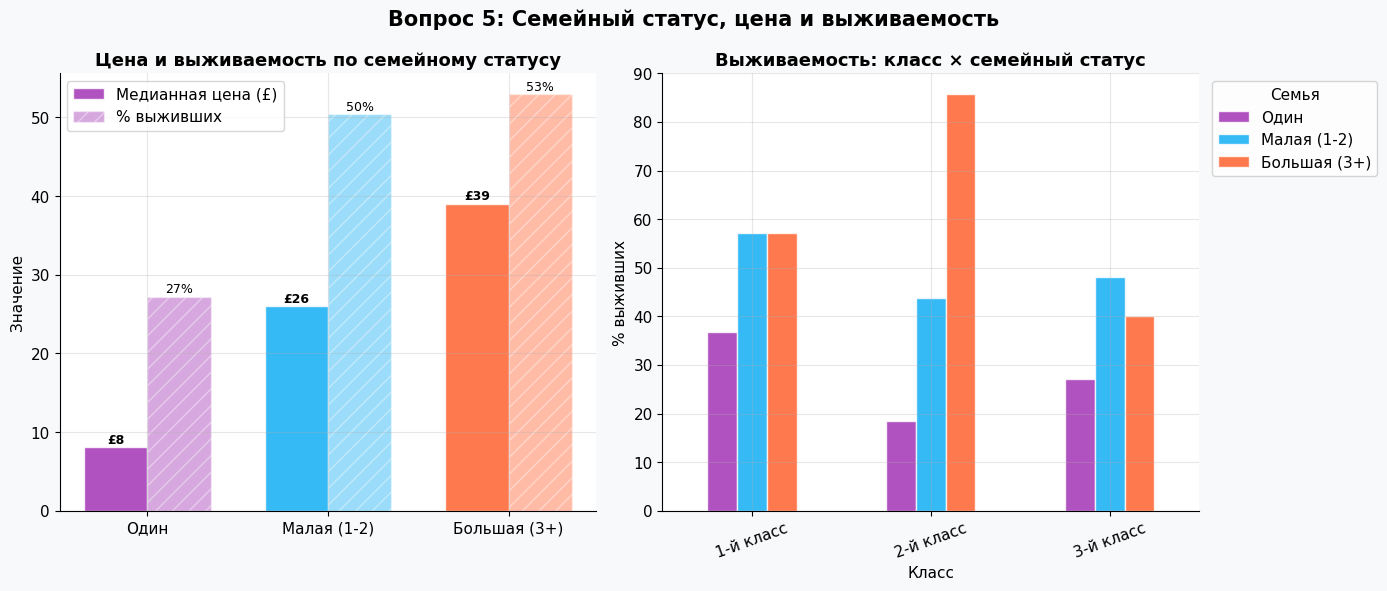

Вывод:
   Тип семьи  Медиана цены  Выживаемость  Кол-во
        Один         8.081         0.272     250
 Малая (1-2)        26.000         0.504     131
Большая (3+)        39.000         0.529      34

Одиночки платили меньше всего и выживали хуже.
Семьи платили больше (групповые билеты) и выживали лучше.


In [8]:
order = ['Один', 'Малая (1-2)', 'Большая (3+)']
family_stats = df.groupby('FamilyGroup').agg(
    median_fare=('Fare', 'median'),
    mean_fare=('Fare', 'mean'),
    survival_rate=('Survived', 'mean'),
    count=('Survived', 'count')
).reset_index()
family_stats['FamilyGroup'] = pd.Categorical(family_stats['FamilyGroup'], categories=order, ordered=True)
family_stats = family_stats.sort_values('FamilyGroup')
fam_colors = ['#9C27B0', '#03A9F4', '#FF5722']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Вопрос 5: Семейный статус, цена и выживаемость', fontsize=15, fontweight='bold')

ax = axes[0]
x = np.arange(len(family_stats))
width = 0.35
bars1 = ax.bar(x - width/2, family_stats['median_fare'], width,
               label='Медианная цена (£)', color=fam_colors, alpha=0.8, edgecolor='white')
bars2 = ax.bar(x + width/2, family_stats['survival_rate'] * 100, width,
               label='% выживших', color=fam_colors, alpha=0.4, edgecolor='white', hatch='//')
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'£{bar.get_height():.0f}', ha='center', fontsize=9, fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.0f}%', ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(family_stats['FamilyGroup'])
ax.set_ylabel('Значение')
ax.set_title('Цена и выживаемость по семейному статусу')
ax.legend()

ax2 = axes[1]
pivot = df.groupby(['PclassLabel', 'FamilyGroup'])['Survived'].mean().unstack() * 100
available_cols = [c for c in order if c in pivot.columns]
pivot[available_cols].plot(kind='bar', ax=ax2, color=fam_colors[:len(available_cols)], alpha=0.8, edgecolor='white')
ax2.set_xlabel('Класс')
ax2.set_ylabel('% выживших')
ax2.set_title('Выживаемость: класс × семейный статус')
ax2.legend(title='Семья', bbox_to_anchor=(1.01, 1), loc='upper left')
ax2.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

print('Вывод:')
print(family_stats[['FamilyGroup', 'median_fare', 'survival_rate', 'count']]
      .rename(columns={'FamilyGroup': 'Тип семьи', 'median_fare': 'Медиана цены',
                       'survival_rate': 'Выживаемость', 'count': 'Кол-во'})
      .round(3).to_string(index=False))
print('\nОдиночки платили меньше всего и выживали хуже.')
print('Семьи платили больше (групповые билеты) и выживали лучше.')

##Итоговый дашборд

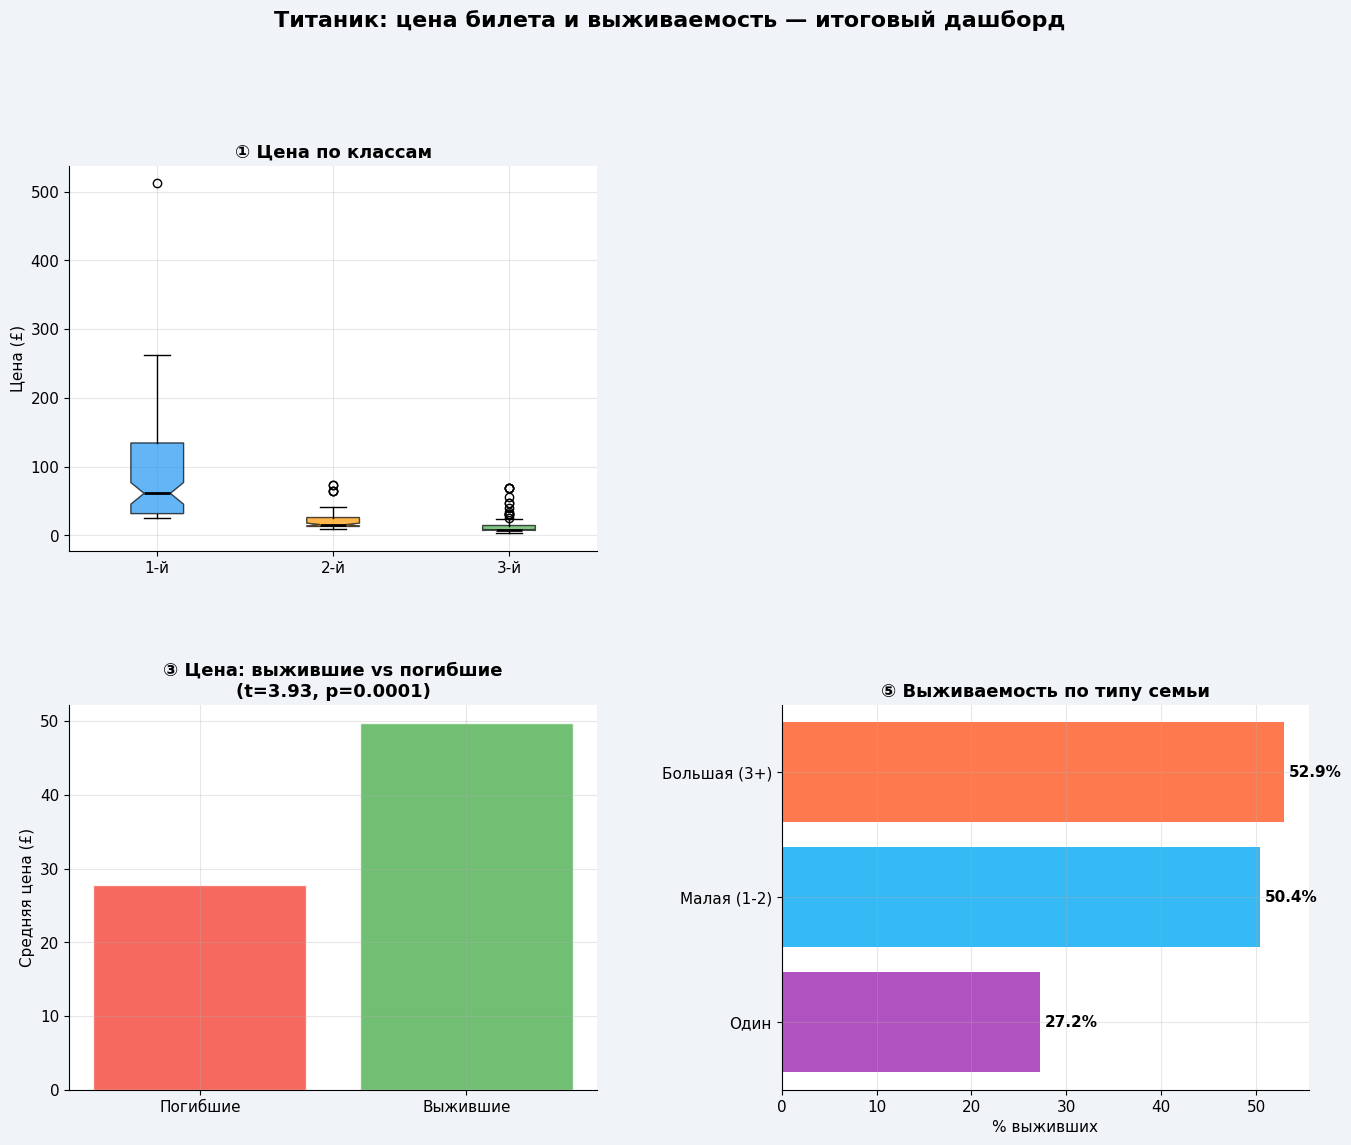

In [9]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 12))
fig.patch.set_facecolor('#F0F4F8')
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# Панель 1: Boxplot цен
ax1 = fig.add_subplot(gs[0, 0])
data_by_class = [df[df['Pclass'] == c]['Fare'].values for c in [1, 2, 3]]
bp = ax1.boxplot(data_by_class, patch_artist=True, notch=True,
                 medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], ['#2196F3', '#FF9800', '#4CAF50']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax1.set_xticks([1, 2, 3])
ax1.set_xticklabels(['1-й', '2-й', '3-й'])
ax1.set_ylabel('Цена (£)')
ax1.set_title('① Цена по классам')


# Панель 2: t-test
ax3 = fig.add_subplot(gs[1, 0])
ax3.bar(['Погибшие', 'Выжившие'], [died_fares.mean(), survived_fares.mean()],
        color=['#F44336', '#4CAF50'], alpha=0.8, edgecolor='white')
ax3.set_ylabel('Средняя цена (£)')
ax3.set_title(f'③ Цена: выжившие vs погибшие\n(t={t_stat:.2f}, p={p_val:.4f})')

# Панель 3: Семья
ax4 = fig.add_subplot(gs[1, 1])
fam_surv = family_stats.set_index('FamilyGroup')['survival_rate'] * 100
ax4.barh(fam_surv.index, fam_surv.values, color=fam_colors, alpha=0.8)
for i, v in enumerate(fam_surv.values):
    ax4.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=11, fontweight='bold')
ax4.set_xlabel('% выживших')
ax4.set_title('⑤ Выживаемость по типу семьи')

fig.suptitle('Титаник: цена билета и выживаемость — итоговый дашборд',
             fontsize=16, fontweight='bold', y=1.01)
plt.show()

##Общие выводы

| # | Вопрос | Вывод |
|---|--------|-------|
| 1 | Распределение цены | 1-й класс: огромный разброс (£26–512). 2-й и 3-й — однородные. |
| 2 | Эффект дохода | Подтверждён: r=0.19, p<0.001. Q1 выживало 30%, Q5 — 52%. |
| 3 | Окупается ли дорогой билет? | Да: £49 vs £28 (p<0.05). Статистически значимо. |
| 4 | Семья и цена | Одиночки выживали хуже (27%). Семьи платили больше и выживали лучше (50–53%). |